In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


# 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

# TARGET_PATH_TO_RESULTS = "experiment_results/"
TARGET_PATH_TO_RESULTS = "experiment_results/backup/"


In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [4]:
from hmm_logic_methods import load_model

In [18]:
selected_model_name = "0_run-8-15-st-baum-welch-alg_model-HLA_A_02_01-1"
MODEL_PATH_USED = f"{TARGET_PATH_TO_RESULTS}{selected_model_name}/"
model = load_model(TARGET_PATH_TO_RESULTS, selected_model_name)

train_peptides = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][1][8]
test_peptides = per_allele_per_kfold_per_length_binders_test[ALLELES[0]][1][8]

# Generate most probable paths

In [19]:
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
import pandas as pd
import numpy as np

# Calculate probs for paths

In [20]:
def get_all_paths_with_probs(model, edge_value="log_probability"):
    df = pd.DataFrame(columns=["path", "prob"])
    # remove empty nodes (for speed up and only possible paths)
    new_graph, name_to_level = convert_graph_to_good_format(model,"", False, precision=4, edge_value=edge_value)
    paths = list(nx.all_simple_paths(new_graph, model.start.name, model.end.name)) # Might be very slow
    print(f"found {len(paths)} paths")
    edge_to_prob = dict()
    for path in paths:
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_edges = path.copy()
        node_from = path_edges.pop(0)
        while path_edges:
            node_to = path_edges.pop(0)
            edge = new_graph.get_edge_data(node_from, node_to)
            edge_to_prob[(node_from, node_to)] = edge['label']
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + edge['label']
            else:
                prob_for_path = prob_for_path * edge['label']
            # print(f"edge {edge}")
            node_from = node_to
        # print(f"Total prob for path is {prob_for_path}")
        row = {"path": path, "prob": prob_for_path}
        df = df.append(row, ignore_index=True)
        df = df.sort_values('prob', ascending=False)
    return df, edge_to_prob

df, edge_to_prob = get_all_paths_with_probs(model)

Model: 0_run-8-15-st-baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-1
{'0_run-8_model-start': 1, 's0_run-8_1': 2, 's0_run-8_11': 2, 's0_run-8_8': 3, 's0_run-8_13': 3, 's0_run-8_0': 4, 's0_run-8_4': 5, 's0_run-8_14': 5, 's0_run-8_12': 6, 's0_run-8_3': 7, 's0_run-8_2': 8, 's0_run-8_6': 8, 's0_run-8_7': 8, 's0_run-8_9': 9, 's0_run-8_10': 9, '0_run-8_model-end': 10, 's0_run-8_5': 4}
found 48 paths


In [21]:
df

,path,prob
0,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-1.338214
1,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-1.908173
2,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-1.937630
3,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-2.096962
4,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-2.507589
5,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-2.666921
6,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-3.368947
7,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-3.856085
8,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-3.968363
9,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-4.127695


In [22]:
def get_state_for_name(model, state_name):
    state = [state for state in model.states if state.name == state_name][0]
    return state

In [23]:
def get_prob_for_path_and_sequence(edge_to_prob, state_path, sequence, edge_value="log_probability"):
    prob_for_path = 0 if edge_value == "log_probability" else 1
    path_nodes = state_path.copy()
    node_from = path_nodes.pop(0)
    emissions = list(sequence)
    while path_nodes:
        node_to = path_nodes.pop(0)
        tr_prob = edge_to_prob[(node_from.name, node_to.name)]
        if node_from.name != model.start.name:
            emission = emissions.pop(0)
            e_prob = node_from.distribution.parameters[0][emission]
            e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + e_prob + tr_prob
            else:
                prob_for_path = prob_for_path * e_prob * tr_prob

        else:
            if edge_value == "log_probability":
                prob_for_path =  prob_for_path + tr_prob
            else:
                prob_for_path =  prob_for_path * tr_prob
        # print(f"edge {edge}")
        node_from = node_to
    return prob_for_path

In [24]:
def get_peptide_to_paths_df(model, peptides, edge_value="log_probability"):
    paths_df, edge_to_prob = get_all_paths_with_probs(model, edge_value=edge_value)
    # df = pd.DataFrame(columns=["peptide", "path", "prob"])
    result_peptides = []
    result_paths = []
    result_probs = []
    for peptide in peptides:
        for path in paths_df['path']:
            state_path = [get_state_for_name(model, state_name) for state_name in path]
            prob_for_path = get_prob_for_path_and_sequence(edge_to_prob, state_path, peptide, edge_value=edge_value)
            result_peptides.append(peptide)
            result_paths.append(path)
            result_probs.append(prob_for_path)
    df = pd.DataFrame({"peptide": result_peptides, "path":result_paths, "prob":result_probs})
    return df



## Get DF for different data

In [25]:
generated_peptides = ["".join(model.sample()) for i in range(2000)]

In [26]:
train_peptide_df = get_peptide_to_paths_df(model, set(train_peptides), edge_value="log_probability")


Model: 0_run-8-15-st-baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-1
{'0_run-8_model-start': 1, 's0_run-8_1': 2, 's0_run-8_11': 2, 's0_run-8_8': 3, 's0_run-8_13': 3, 's0_run-8_0': 4, 's0_run-8_4': 5, 's0_run-8_14': 5, 's0_run-8_12': 6, 's0_run-8_3': 7, 's0_run-8_2': 8, 's0_run-8_6': 8, 's0_run-8_7': 8, 's0_run-8_9': 9, 's0_run-8_10': 9, '0_run-8_model-end': 10, 's0_run-8_5': 4}
found 48 paths


In [27]:
test_peptide_df = get_peptide_to_paths_df(model, set(test_peptides), edge_value="log_probability")


Model: 0_run-8-15-st-baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-1
{'0_run-8_model-start': 1, 's0_run-8_1': 2, 's0_run-8_11': 2, 's0_run-8_8': 3, 's0_run-8_13': 3, 's0_run-8_0': 4, 's0_run-8_4': 5, 's0_run-8_14': 5, 's0_run-8_12': 6, 's0_run-8_3': 7, 's0_run-8_2': 8, 's0_run-8_6': 8, 's0_run-8_7': 8, 's0_run-8_9': 9, 's0_run-8_10': 9, '0_run-8_model-end': 10, 's0_run-8_5': 4}
found 48 paths


In [28]:
generated_peptide_df = get_peptide_to_paths_df(model, set(generated_peptides), edge_value="log_probability")

Model: 0_run-8-15-st-baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-1
{'0_run-8_model-start': 1, 's0_run-8_1': 2, 's0_run-8_11': 2, 's0_run-8_8': 3, 's0_run-8_13': 3, 's0_run-8_0': 4, 's0_run-8_4': 5, 's0_run-8_14': 5, 's0_run-8_12': 6, 's0_run-8_3': 7, 's0_run-8_2': 8, 's0_run-8_6': 8, 's0_run-8_7': 8, 's0_run-8_9': 9, 's0_run-8_10': 9, '0_run-8_model-end': 10, 's0_run-8_5': 4}
found 48 paths


In [29]:
train_peptide_df

,peptide,path,prob
0,PINGNGKQ,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-28.354790
1,PINGNGKQ,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-90.745816
2,PINGNGKQ,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-30.908684
3,PINGNGKQ,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-28.427602
4,PINGNGKQ,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-93.299710
...,...,...,...
114379,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-38.023748
114380,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-42.898873
114381,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-42.635597
114382,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-42.280633


# Plot UMAP

In [30]:
unique_paths = train_peptide_df['path'].apply(str).unique()

In [31]:
path_to_index = {path : i for  i , path in enumerate(unique_paths)}

In [32]:
train_peptide_df['path_index'] = train_peptide_df["path"].map(str).map(path_to_index)
train_peptide_df['dataset'] = 'Train'
test_peptide_df['path_index'] = test_peptide_df["path"].map(str).map(path_to_index)
test_peptide_df['dataset'] = 'Test'
generated_peptide_df['path_index']  = generated_peptide_df["path"].map(str).map(path_to_index)
generated_peptide_df['dataset'] = 'Generated'

In [33]:
train_peptide_df

,peptide,path,prob,path_index,dataset
0,PINGNGKQ,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-28.354790,0,Train
1,PINGNGKQ,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-90.745816,1,Train
2,PINGNGKQ,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-30.908684,2,Train
3,PINGNGKQ,"[0_run-8_model-start, s0_run-8_11, s0_run-8_8,...",-28.427602,3,Train
4,PINGNGKQ,"[0_run-8_model-start, s0_run-8_1, s0_run-8_13,...",-93.299710,4,Train
...,...,...,...,...,...
114379,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-38.023748,43,Train
114380,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-42.898873,44,Train
114381,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-42.635597,45,Train
114382,VLFEDVYE,"[0_run-8_model-start, s0_run-8_1, s0_run-8_8, ...",-42.280633,46,Train


In [34]:
train_pivot = train_peptide_df.pivot(index='peptide', columns='path_index', values='prob')
test_pivot = test_peptide_df.pivot(index='peptide', columns='path_index', values='prob')
generated_pivot = generated_peptide_df.pivot(index='peptide', columns='path_index', values='prob')
train_pivot

path_index,0,1,2,3,4,5,6,7,8,9,...,38,39,40,41,42,43,44,45,46,47
peptide,,,,,,,,,,,,,,,,,,,,,
AADGVIRL,-20.007837,-21.852401,-40.004180,-22.177400,-41.848744,-24.021965,-23.238160,-41.225142,-43.234502,-25.407723,...,-31.403273,-50.451014,-34.175920,-33.115030,-33.402874,-53.399216,-35.572437,-54.620179,-38.345084,-37.284195
AADKPLAF,-22.155055,-23.827328,-23.082828,-22.399064,-24.755102,-24.071338,-25.385378,-25.193239,-26.313151,-25.629387,...,-31.624936,-34.419111,-33.508136,-34.372800,-35.377801,-36.305574,-35.621810,-38.415985,-37.505009,-38.369674
AAEFLKQV,-21.494183,-25.629584,-30.548248,-21.848204,-34.683649,-25.983605,-27.036506,-24.641421,-36.090571,-27.390527,...,-31.074076,-33.867293,-40.974513,-41.729166,-34.868057,-43.922122,-35.222078,-38.015295,-45.122515,-45.877168
AAERRGPL,-23.731998,-28.293391,-23.546368,-23.161401,-28.107761,-27.722794,-29.274320,-24.767330,-29.088690,-28.703723,...,-32.387273,-33.993202,-35.159920,-36.839191,-37.531864,-37.346234,-36.961267,-38.567196,-39.733914,-41.413185
AAKFRVGS,-26.549233,-29.253661,-25.136267,-28.081002,-27.840696,-30.785430,-30.660583,-29.734012,-29.247617,-32.192352,...,-37.306874,-38.959884,-36.702740,-36.279644,-39.923106,-38.510141,-41.454876,-43.107885,-40.850741,-40.427646
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YTREYEKL,-23.991170,-25.597795,-30.500363,-24.063982,-32.106988,-25.670607,-28.036012,-31.721326,-34.545205,-28.108824,...,-33.399920,-41.057263,-36.172567,-37.208429,-36.443814,-42.953007,-36.516626,-44.173969,-39.289273,-40.325135
YVCFLILI,-26.216368,-26.573658,-26.971845,-28.264288,-27.329136,-28.621578,-27.980580,-27.444212,-28.736057,-30.028500,...,-37.600225,-36.780150,-41.121468,-40.182223,-39.700307,-40.455784,-41.748227,-40.928151,-45.269470,-44.330224
YVIGQKGS,-28.061413,-27.581017,-26.648448,-29.593183,-26.168052,-29.112787,-28.966776,-31.246192,-27.553810,-30.498545,...,-38.929121,-40.582130,-38.324986,-37.901891,-41.566516,-40.153550,-43.098285,-44.751294,-42.494150,-42.071055


In [35]:
import umap
from sklearn.preprocessing import StandardScaler

def get_reducer(train_df):
    reducer = umap.UMAP()
    data = train_df.values
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    reducer.fit(scaled_data)
    return reducer, scaler

def get_embedding(reducer, scaler,  data):
    scaled_data = scaler.fit_transform(data)
    return reducer.transform(scaled_data)

reducer, scaler = get_reducer(pd.concat([train_pivot]))

d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\sklearn\manifold\_spectral_embedding.py:260: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


In [36]:
train_embedding = get_embedding(reducer, scaler, train_pivot)
test_embedding = get_embedding(reducer, scaler, test_pivot)
generated_embedding = get_embedding(reducer, scaler, generated_pivot)

In [37]:
train_embedding_df = pd.DataFrame(train_embedding)
train_embedding_df['dataset'] = 'Train'
train_embedding_df['peptide'] = train_pivot.index.values
test_embedding_df = pd.DataFrame(test_embedding)
test_embedding_df['dataset'] = 'Test'
test_embedding_df['peptide'] = test_pivot.index.values
generated_embedding_df = pd.DataFrame(generated_embedding)
generated_embedding_df['dataset'] = 'Generated'
generated_embedding_df['peptide'] = generated_pivot.index.values
total_df = pd.concat([train_embedding_df,
                      test_embedding_df,
                      generated_embedding_df
                      ])
total_pivot = pd.concat([train_pivot, test_pivot, generated_pivot])

total_df = total_df.sample(frac=1)

In [38]:
generated_embedding_df

,0,1,dataset,peptide
0,-0.089463,0.080467,Generated,AAFQPEEM
1,-12.053847,-1.401216,Generated,AAIFVLRV
2,11.098340,11.640182,Generated,AAIYAPKA
3,2.399092,-4.468976,Generated,AALENKLL
4,10.541180,-12.851991,Generated,ADDLLGRL
...,...,...,...,...
1995,1.628358,1.124329,Generated,YVDYEWYR
1996,1.100187,11.255818,Generated,YVLARDKV
1997,16.102160,2.637030,Generated,YVSSEYIV
1998,8.494091,-7.757353,Generated,YYGYIINR


In [39]:
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
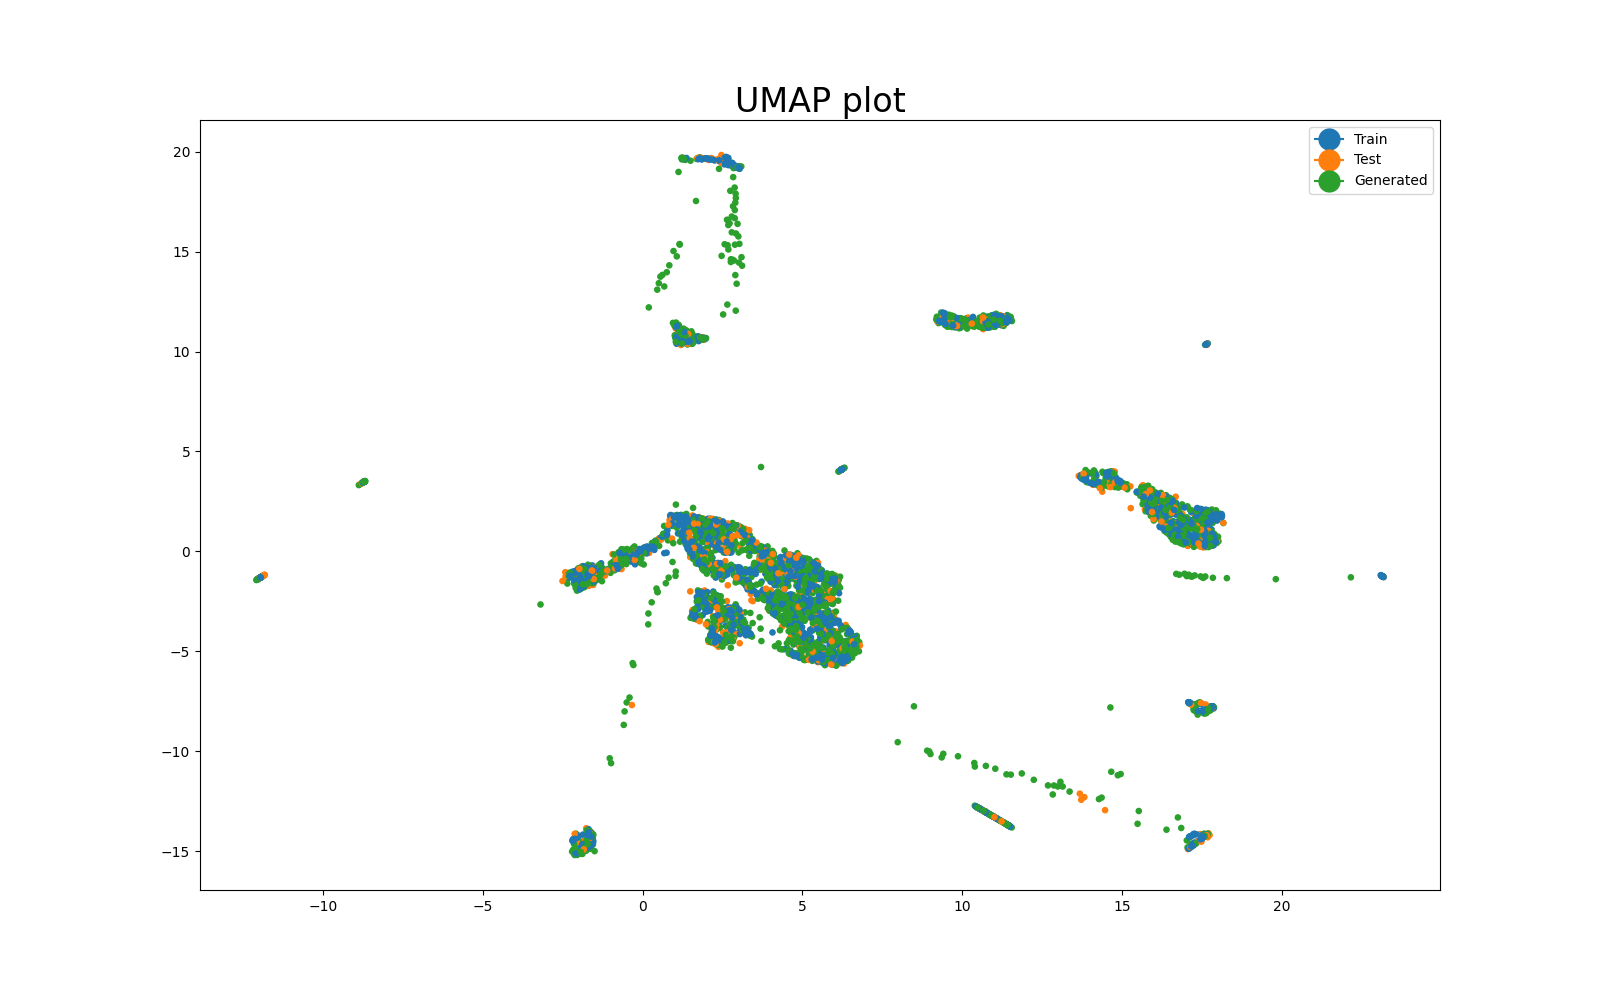

In [41]:
%matplotlib widget

def save_figure_to_file(fig, dir, filename):
    fig.savefig(dir + filename, format="png", bbox_inches='tight', transparent=False)

#using matplotlib only
fig,ax = plt.subplots(figsize=(16, 10))

x =  total_df[0]
y =  total_df[1]
names = total_df['peptide'].values
color_choices = {"Train":0, "Test":1, "Generated":2}
color_to_dataset = {item:key for key, item in color_choices.items()}
c = total_df.dataset.map(color_choices).values

sc = plt.scatter(
    x,
    y,
    s=14,
    c=[sns.color_palette()[x] for x in c],
)


annot = ax.annotate("", xy=(0,0), xytext=(20,20),textcoords="offset points",
                    bbox=dict(boxstyle="round", fc="w"),
                    arrowprops=dict(arrowstyle="->"))
annot.set_visible(False)



def update_annot(ind):
    pos = sc.get_offsets()[ind["ind"][0]]
    annot.xy = pos
    hover_indexes = list(map(str,ind["ind"]))
    hover_peptides = [names[n] for n in ind["ind"]]
    hover_dataset = [color_to_dataset[c[n]] for n in ind["ind"]]
    text = "\n".join([f"{idx}, {peptide}, {dataset}" for idx, peptide, dataset in zip(hover_indexes, hover_peptides,hover_dataset)])
    annot.set_text(text)
    annot.get_bbox_patch().set_facecolor(sns.color_palette()[c[ind["ind"][0]]])
    annot.get_bbox_patch().set_alpha(0.4)

def hover(event):
    vis = annot.get_visible()
    if event.inaxes == ax:
        cont, ind = sc.contains(event)
        if cont:
            update_annot(ind)
            annot.set_visible(True)
            fig.canvas.draw_idle()
        else:
            if vis:
                annot.set_visible(False)
                fig.canvas.draw_idle()

fig.canvas.mpl_connect("motion_notify_event", hover)


fig.canvas.toolbar_visible = True
fig.canvas.header_visible = True
fig.canvas.resizable = True


legend_elements = [Line2D([0], [0], marker='o', color=sns.color_palette()[c_inx], label=label, markersize=15)
                   for label, c_inx  in color_choices.items()]

plt.legend(handles=legend_elements)
plt.title('UMAP plot', fontsize=24)
plt.show()

save_figure_to_file(fig, MODEL_PATH_USED, "umap_matplotlib.png")

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
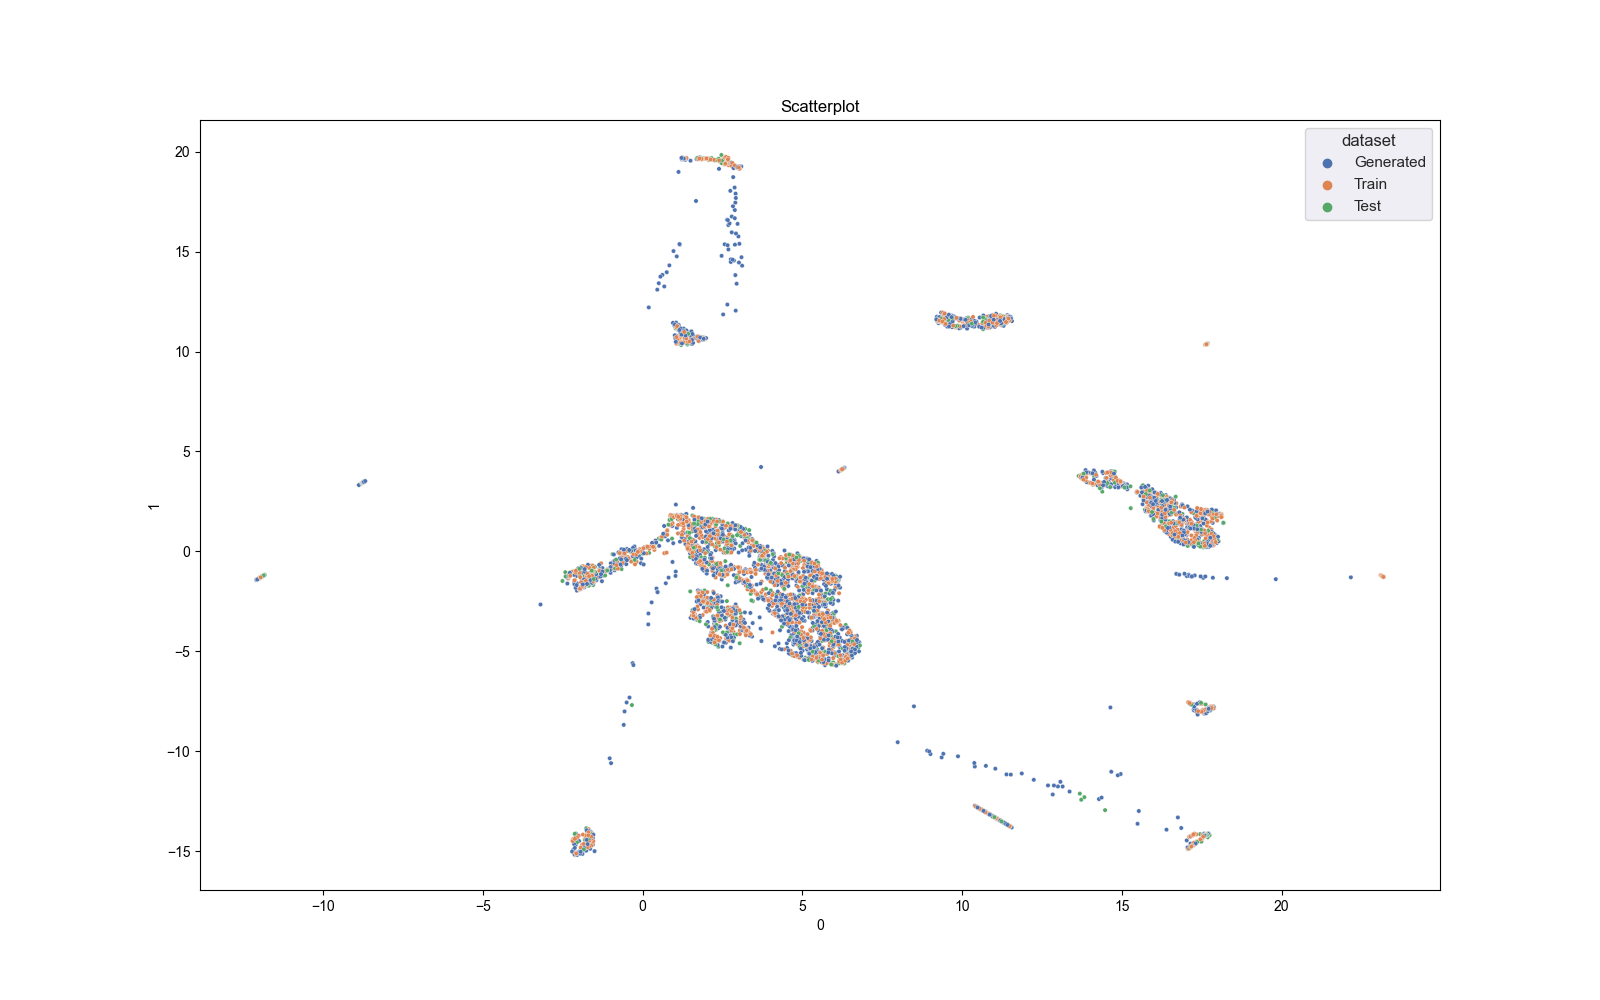

In [42]:
# using
import mplcursors

fig,ax = plt.subplots(figsize=(16, 10))

sns.set_theme(style="dark")
ax = sns.scatterplot(data=total_df, x=total_df.columns[0], y=total_df.columns[1], hue="dataset",ax=ax, picker=4, s=10,
                     c=[sns.color_palette()[x] for x in total_df.dataset.map({"Train":0, "Test":1, "Generated":2})])
ax.set_title(f"Scatterplot")

peptides = total_df['peptide'].values
datasets = total_df['dataset'].values

cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}"))


save_figure_to_file(fig, MODEL_PATH_USED, "umap_seaborn.png")
plt.show()

## Cluster result image

In [43]:
#Import required module
from sklearn.cluster import KMeans

#Initialize the class object
kmeans = KMeans(n_clusters= 15)
df = total_df[[0, 1]].values
#predict the labels of clusters.
labels = kmeans.fit_predict(df)

unique_labels = list(set(labels))
len(labels), unique_labels

(4981, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])

In [44]:
clustered_df = total_df.copy()
clustered_df['label'] = labels

In [45]:
clustered_df

,0,1,dataset,peptide,label
1581,6.099597,-1.739815,Generated,SLAKVAFT,12
1154,9.706923,11.260620,Train,LKPEVDKL,5
1221,4.385668,-3.265342,Train,LLHVIVCF,12
212,4.945321,-0.479813,Test,KPSDLIDK,12
462,6.168180,-4.786728,Generated,HSLKIVGL,1
...,...,...,...,...,...
2037,1.382214,1.500656,Train,TLWVDPYE,4
1457,17.387747,-7.999720,Train,LYLIQYLL,14
703,2.501280,-4.765863,Generated,KLVRLLLK,8
2287,2.417384,-1.165684,Train,YFDPANGK,4


# Plot clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
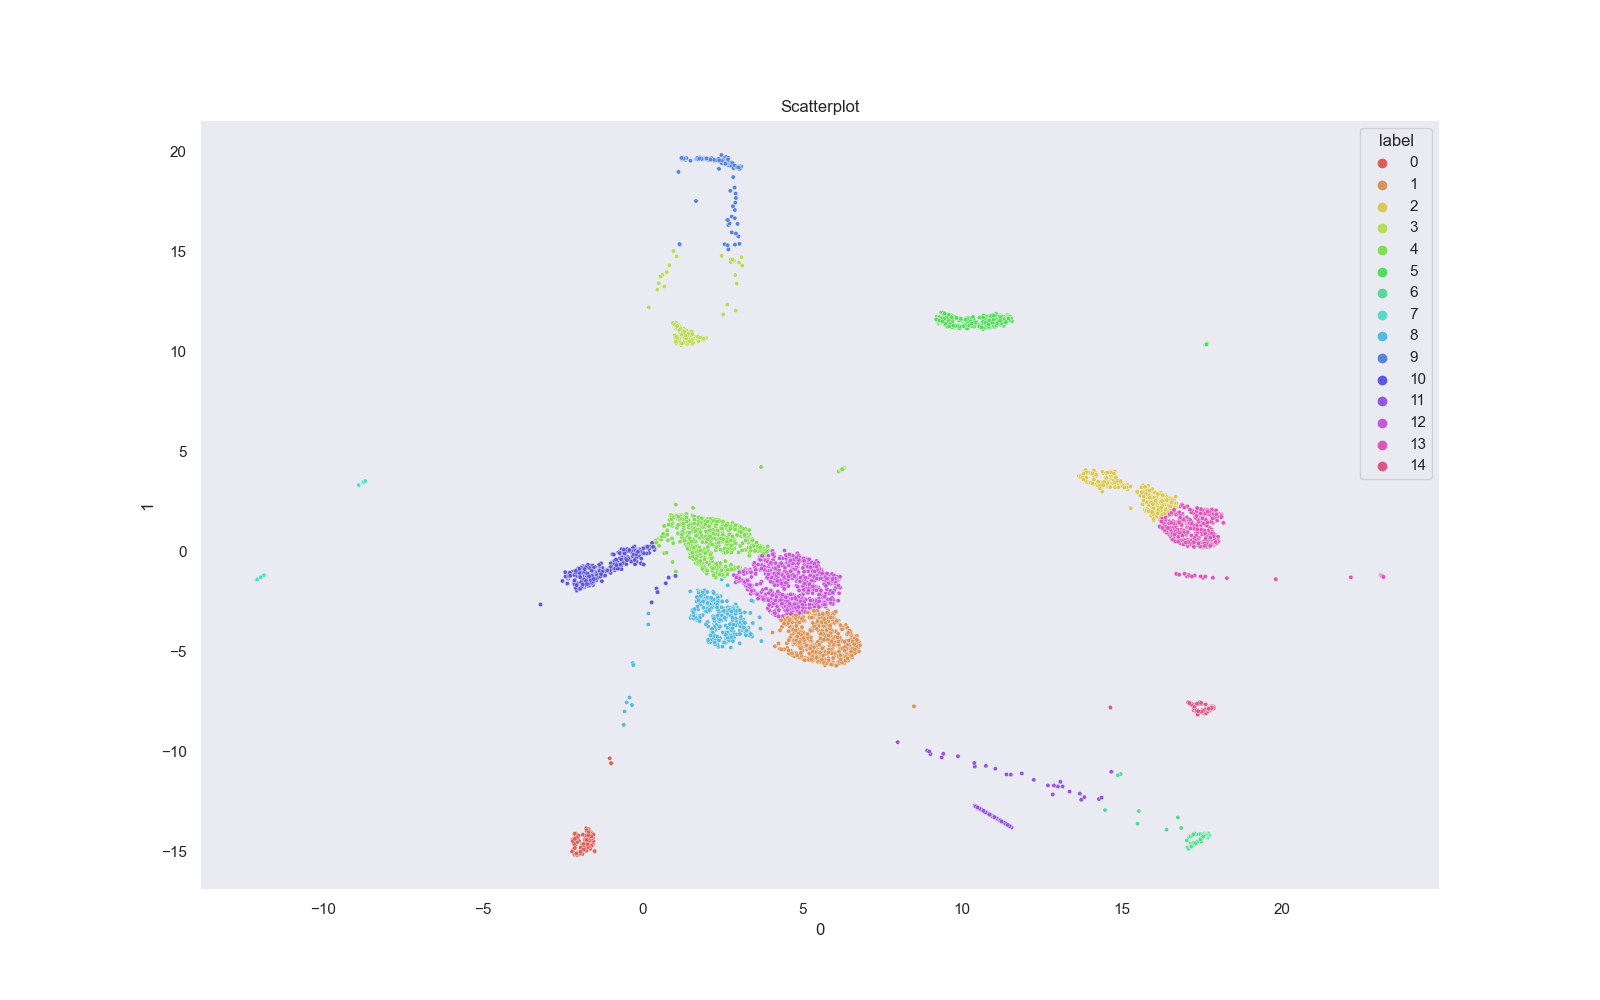

In [46]:
fig,ax = plt.subplots(figsize=(16, 10))



# sns.set_theme(style="dark")

ax = sns.scatterplot(data=clustered_df, x=clustered_df.columns[0], y=clustered_df.columns[1], hue="label",ax=ax, s=10, palette=sns.color_palette("hls", len(unique_labels)))
ax.set_title(f"Scatterplot")

peptides = clustered_df['peptide'].values
datasets = clustered_df['dataset'].values

cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}"))

save_figure_to_file(fig, MODEL_PATH_USED, "clustered_umap.png")

In [47]:
clustered_df

,0,1,dataset,peptide,label
1581,6.099597,-1.739815,Generated,SLAKVAFT,12
1154,9.706923,11.260620,Train,LKPEVDKL,5
1221,4.385668,-3.265342,Train,LLHVIVCF,12
212,4.945321,-0.479813,Test,KPSDLIDK,12
462,6.168180,-4.786728,Generated,HSLKIVGL,1
...,...,...,...,...,...
2037,1.382214,1.500656,Train,TLWVDPYE,4
1457,17.387747,-7.999720,Train,LYLIQYLL,14
703,2.501280,-4.765863,Generated,KLVRLLLK,8
2287,2.417384,-1.165684,Train,YFDPANGK,4


## Analyze clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
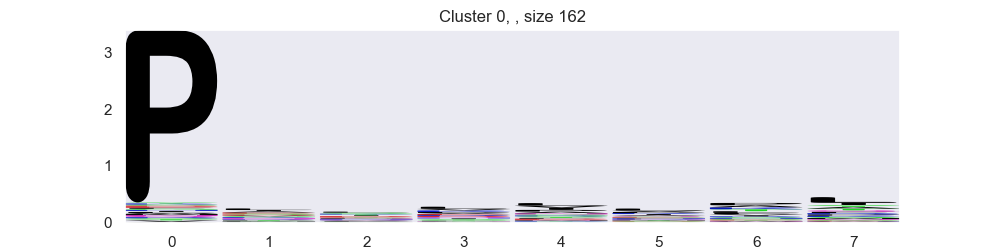

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
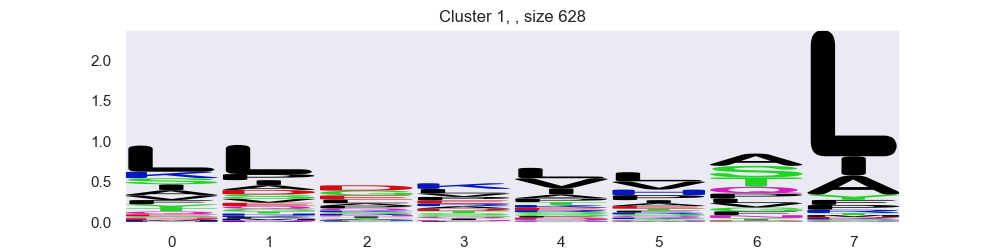

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
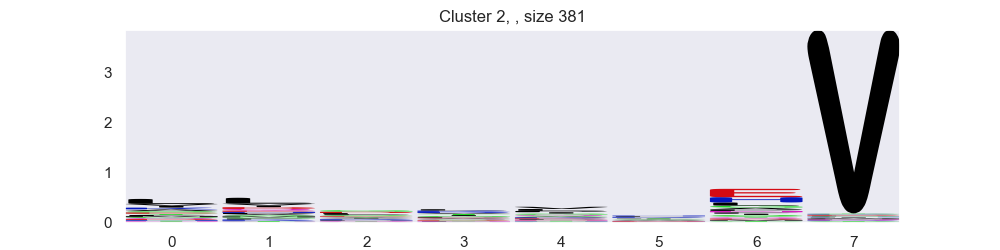

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
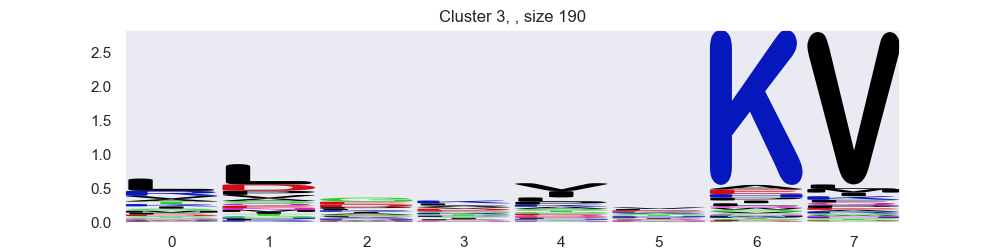

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
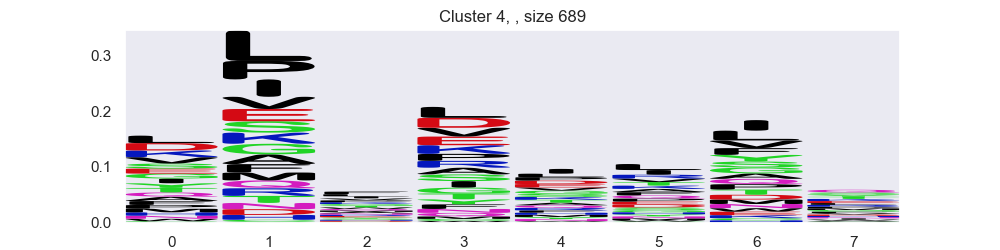

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
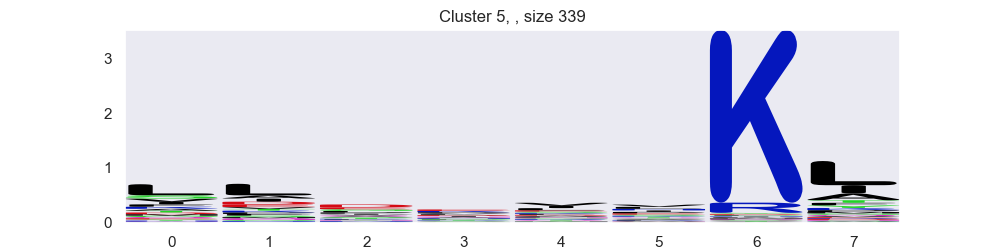

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
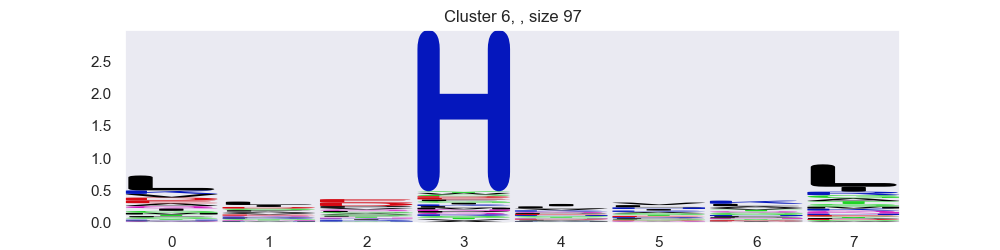

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
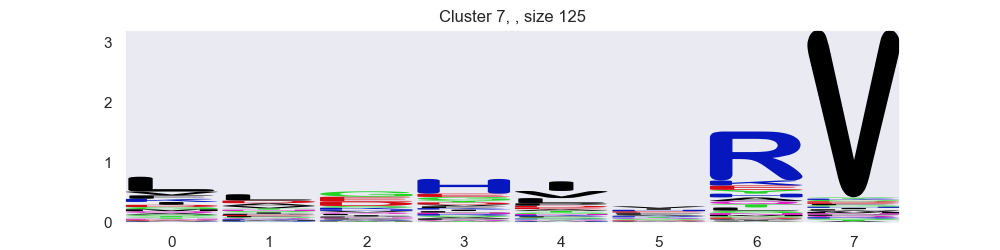

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
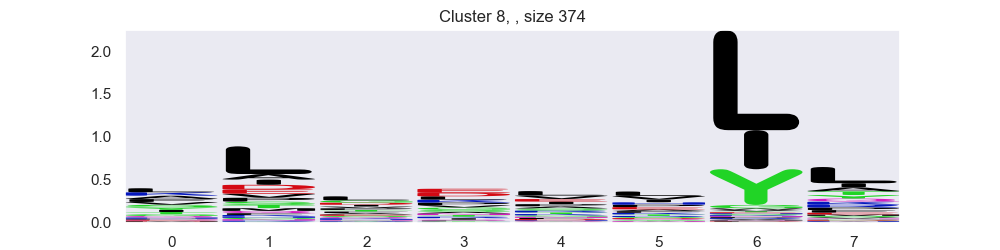

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
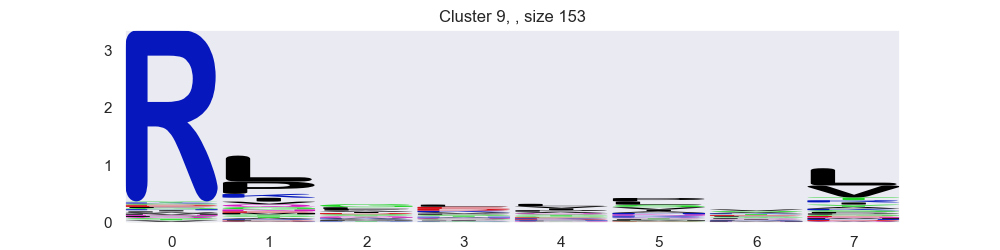

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
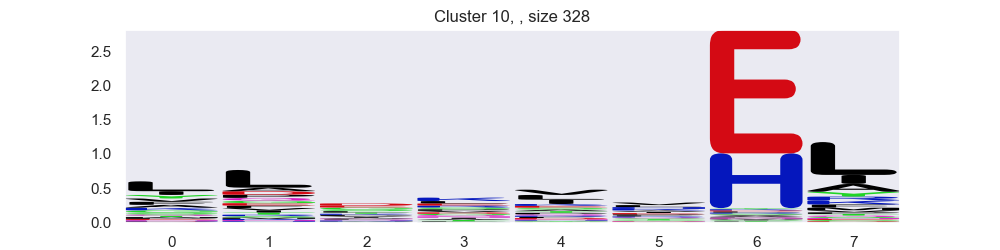

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
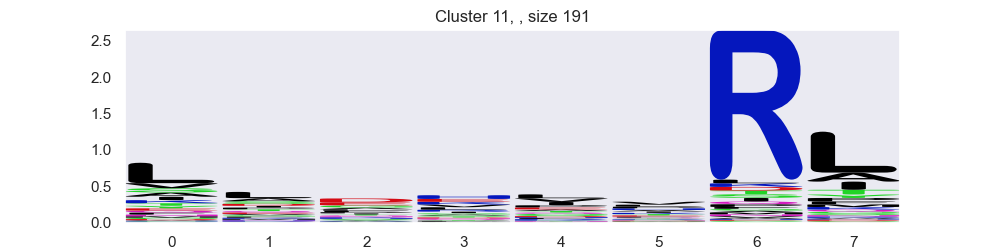

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
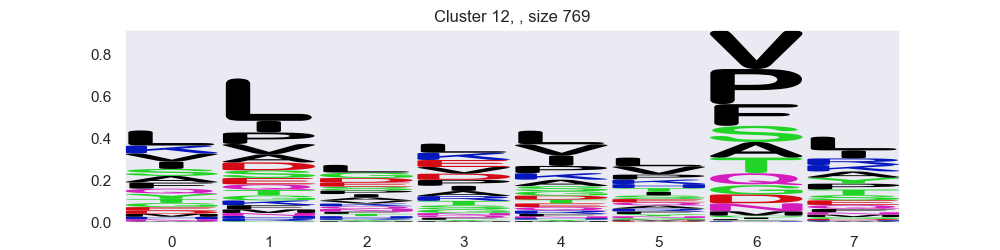

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
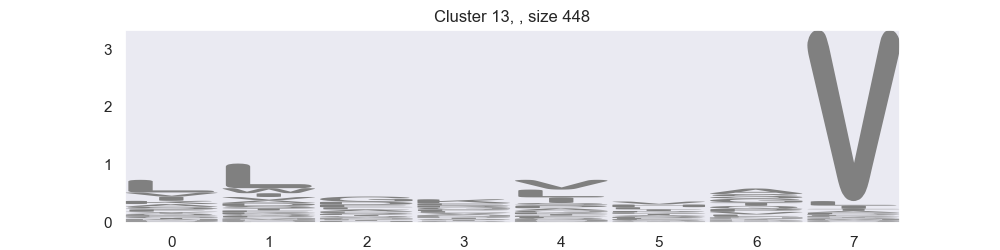

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
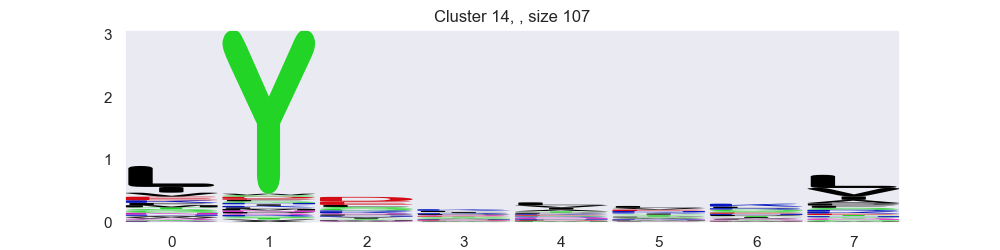

In [48]:
import logomaker
unique_datasets = set(clustered_df.dataset.values)
for cluster_label in unique_labels:
    peptides = clustered_df[clustered_df['label'] == cluster_label]['peptide'].values
    matrix = logomaker.alignment_to_matrix(peptides)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f"Cluster {cluster_label}, , size {len(peptides)}")

C:\Users\denkl\AppData\Local\Temp/ipykernel_14756/2946069312.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=1, figsize=[6, 1])


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
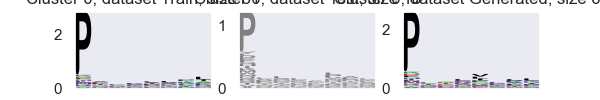

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
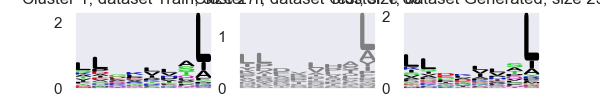

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
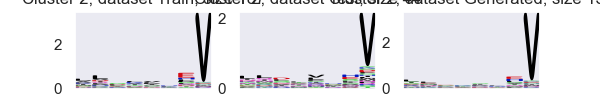

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
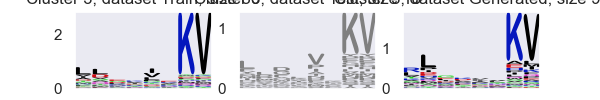

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
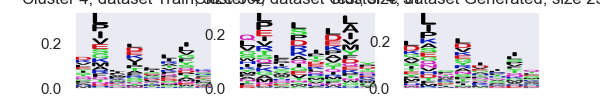

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
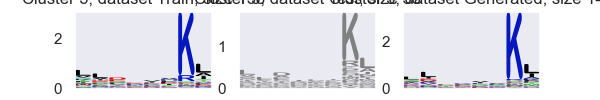

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
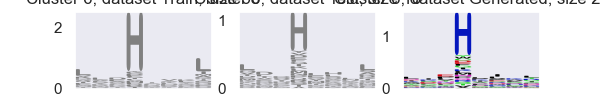

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
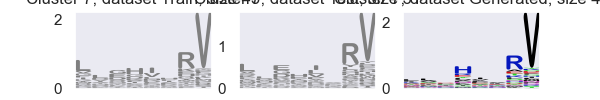

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
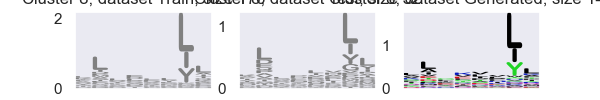

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
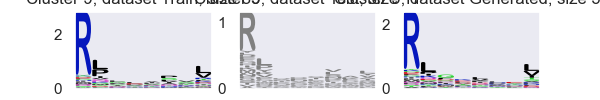

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
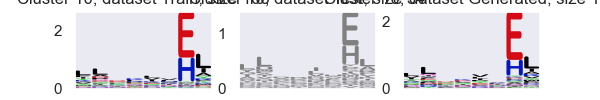

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
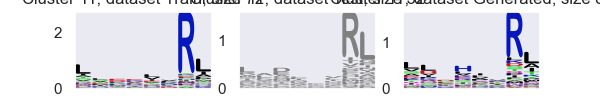

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
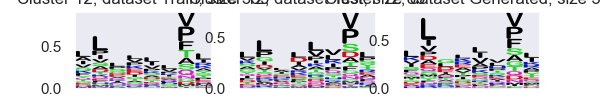

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
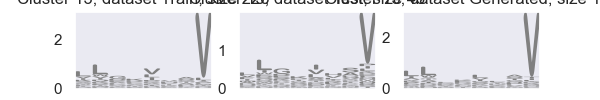

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
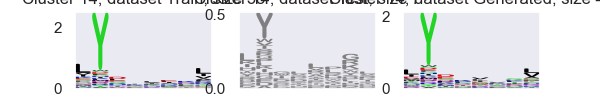

In [49]:
unique_datasets = set(clustered_df.dataset.values)
for cluster_label in unique_labels:
    fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=1, figsize=[6, 1])
    for dataset_index, dataset_type in enumerate(unique_datasets):
        peptides = clustered_df[(clustered_df['label'] == cluster_label) & (clustered_df['dataset'] == dataset_type)]['peptide'].values
        matrix = logomaker.alignment_to_matrix(peptides)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',ax=axes[dataset_index])
        ww_logo.ax.set_title(f"Cluster {cluster_label}, dataset {dataset_type}, size {len(peptides)}")


# PCA

In [51]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA


def getPCA(df_concat, n_components=2, target_col="dataset"):
    X = df_concat.drop(columns=target_col).values
    pca = PCA(n_components=n_components)
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(df_concat, pca, target_col="dataset"):
    Y = df_concat[target_col].values
    X = df_concat.drop(columns=target_col).values
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result)
    df[target_col] = Y
    return df

In [53]:
train_pivot['dataset'] = 'Train'
test_pivot['dataset'] = 'Test'
generated_pivot['dataset'] = 'Generated'

total_pivot = pd.concat([train_pivot])
total_total_pivot = pd.concat([train_pivot, test_pivot, generated_pivot])

In [54]:
pca = getPCA(total_pivot)

Explained variation per principal component: [0.82313419 0.1183037 ]


In [55]:
total_embedding = get_pca_embedding(total_total_pivot, pca)
total_embedding['peptide'] = total_total_pivot.index.values
total_embedding['dataset'] = total_total_pivot['dataset'].values


total_embedding = total_embedding.sample(frac=1)

peptides = total_embedding['peptide'].values
datasets = total_total_pivot['dataset'].values

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
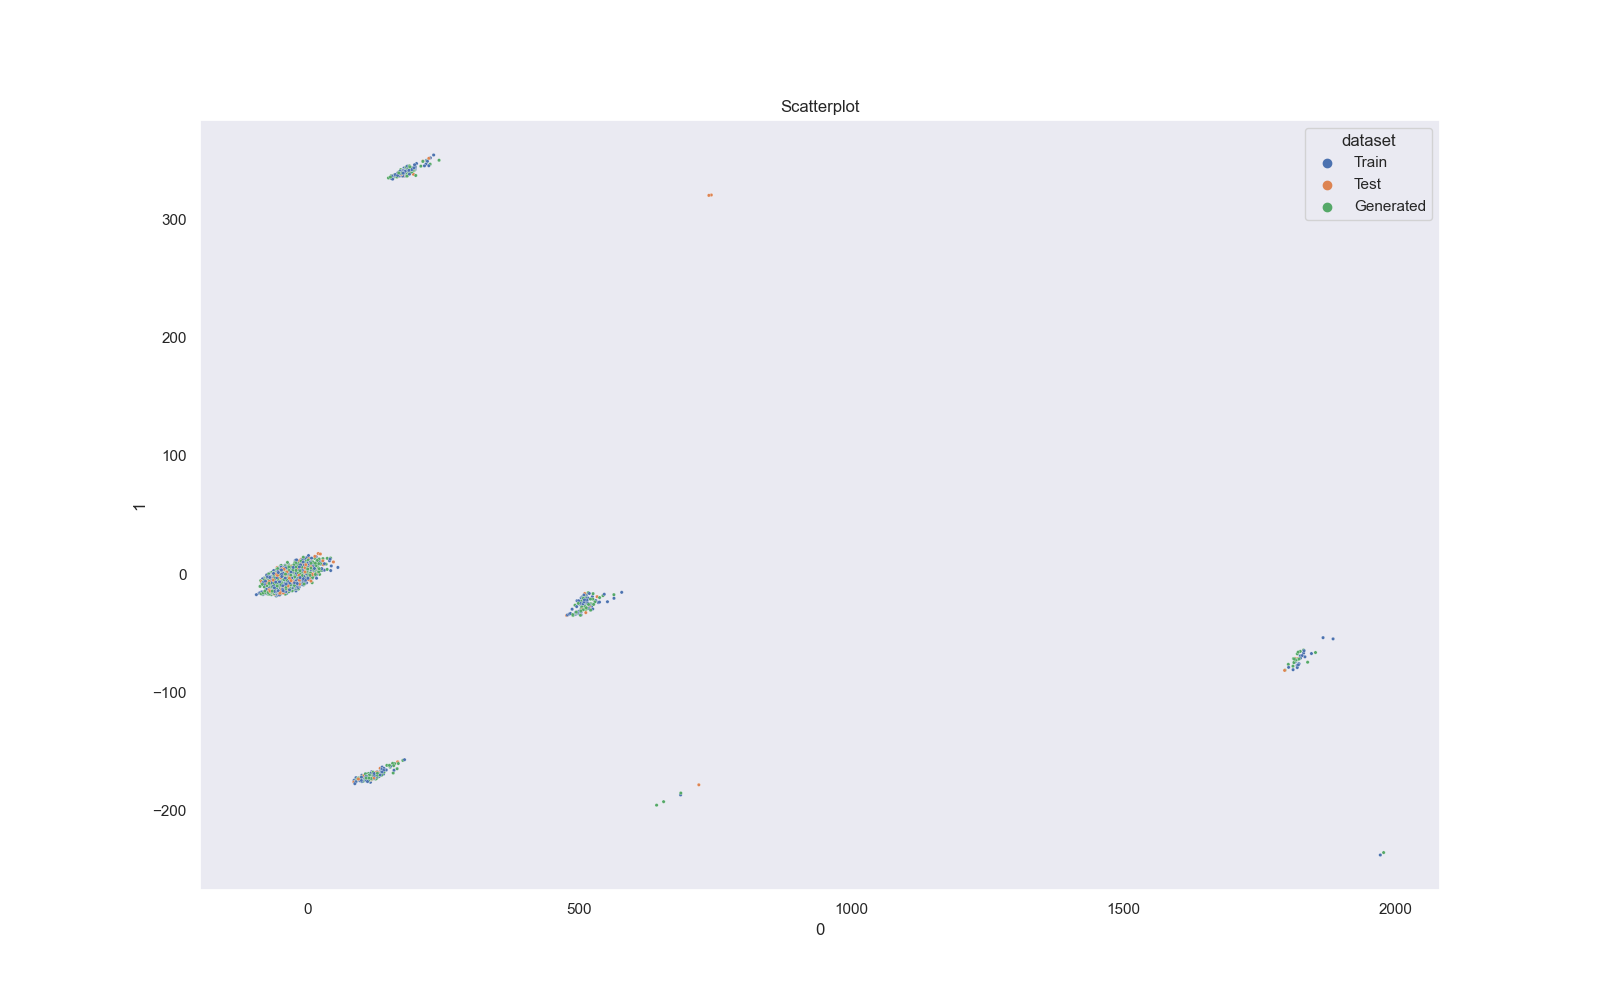

In [56]:
plt.figure(figsize=(16, 10))
sns.set_theme(style="dark")

ax = sns.scatterplot(data=total_embedding, x=total_embedding.columns[0], y=total_embedding.columns[1], hue="dataset", s=6)
ax.set_title(f"Scatterplot")
fig =  ax.get_figure()

cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}"))

save_figure_to_file(fig, TARGET_PATH_TO_RESULTS, "pca.png")

In [57]:
total_embedding

,0,1,dataset,peptide
1034,-41.792702,-13.279988,Train,LDTSRHYL
506,-61.012498,2.483287,Train,GLGPVAAV
1267,-58.680047,-7.361248,Train,LLWKPVTV
2948,-48.255348,-6.860745,Test,YDDKGVGL
3971,-66.548957,-12.532381,Generated,LLLITILT
...,...,...,...,...
2625,-50.240833,-16.214074,Test,LDDLKVEL
1887,-52.951695,1.362753,Train,SLLEKEHD
18,-46.727038,-2.008252,Train,AEIAKAEL
1520,13.369147,4.777160,Train,MVDHVTEV


In [58]:
#Import required module
from sklearn.cluster import KMeans

#Initialize the class object
kmeans = KMeans(n_clusters= 8)
df = total_embedding[[0, 1]].values
#predict the labels of clusters.
labels = kmeans.fit_predict(df)

unique_labels = list(set(labels))
len(labels), unique_labels

(4981, [0, 1, 2, 3, 4, 5, 6, 7])

In [59]:
clustered_df = total_embedding.copy()
clustered_df['label'] = labels

In [60]:
clustered_df

,0,1,dataset,peptide,label
1034,-41.792702,-13.279988,Train,LDTSRHYL,0
506,-61.012498,2.483287,Train,GLGPVAAV,5
1267,-58.680047,-7.361248,Train,LLWKPVTV,5
2948,-48.255348,-6.860745,Test,YDDKGVGL,5
3971,-66.548957,-12.532381,Generated,LLLITILT,5
...,...,...,...,...,...
2625,-50.240833,-16.214074,Test,LDDLKVEL,5
1887,-52.951695,1.362753,Train,SLLEKEHD,5
18,-46.727038,-2.008252,Train,AEIAKAEL,0
1520,13.369147,4.777160,Train,MVDHVTEV,6


# check plot with clusters

<function __main__.<lambda>(sel)>

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
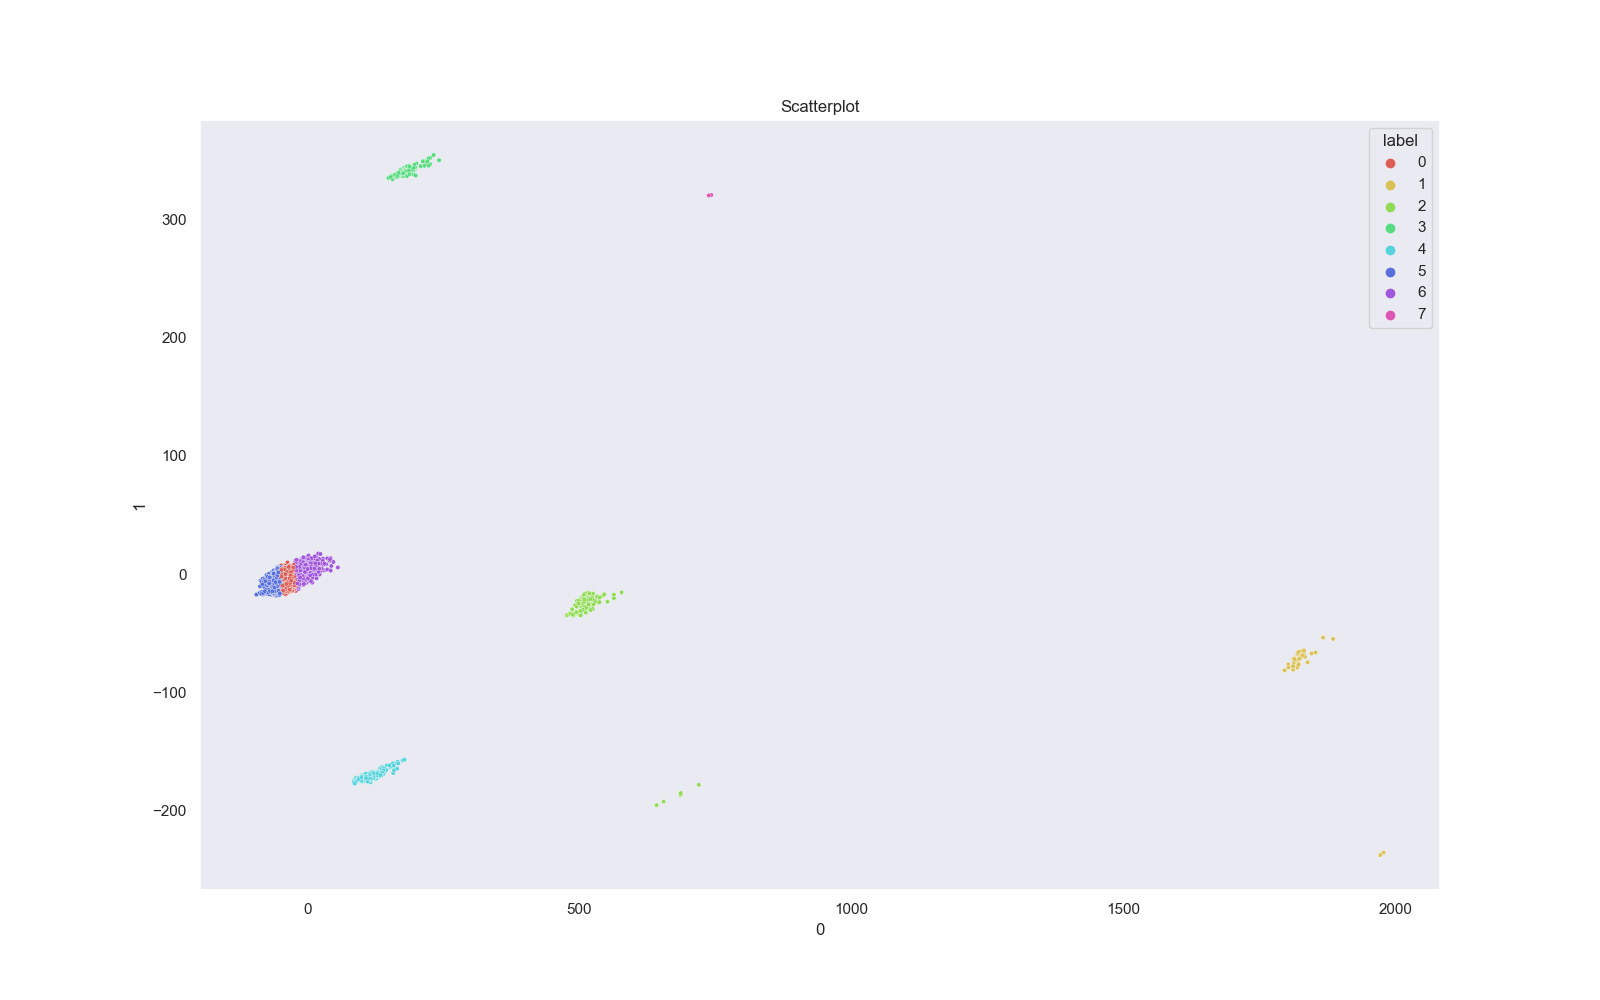

In [63]:
fig,ax = plt.subplots(figsize=(16, 10))


# sns.set_theme(style="dark")

ax = sns.scatterplot(data=clustered_df, x=clustered_df.columns[0], y=clustered_df.columns[1], hue="label",ax=ax, s=10, palette=sns.color_palette("hls", len(unique_labels)))
ax.set_title(f"Scatterplot")

peptides = clustered_df['peptide'].values
datasets = clustered_df['dataset'].values


cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}"))


## Analyze clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
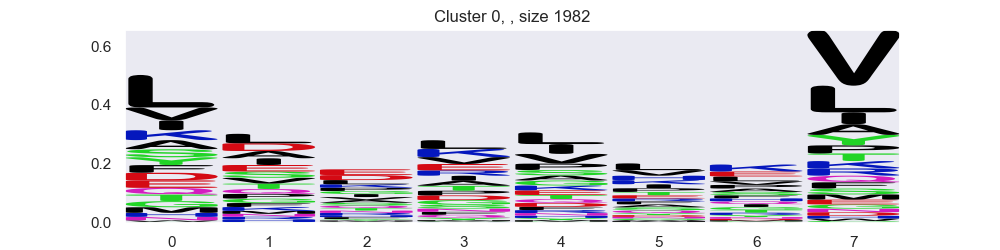

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
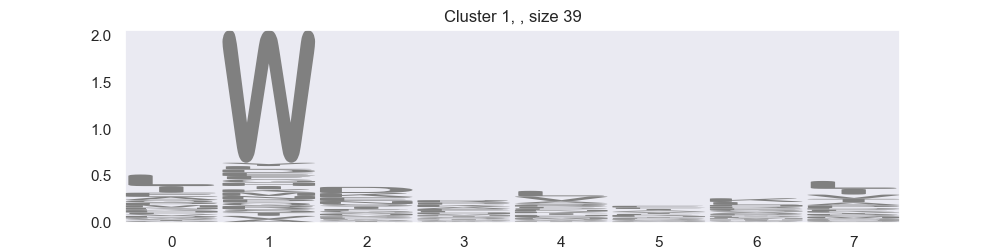

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
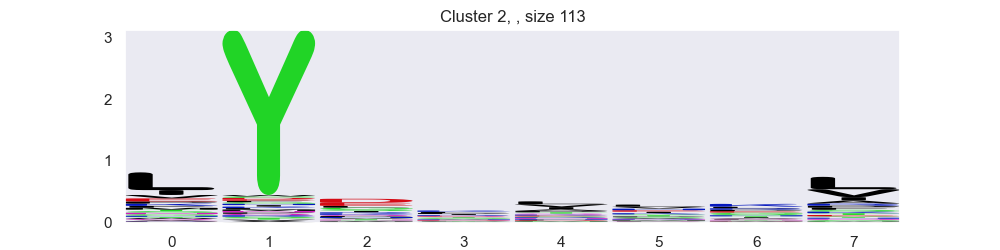

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
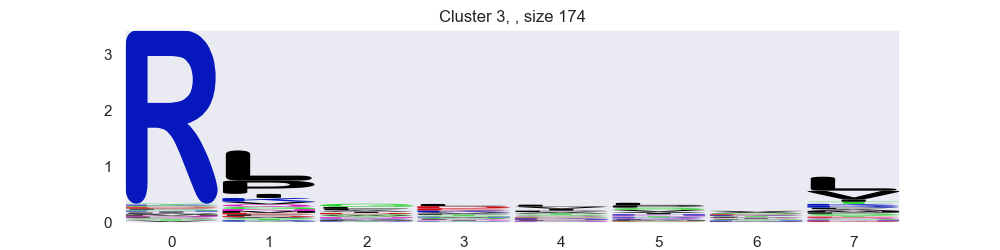

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
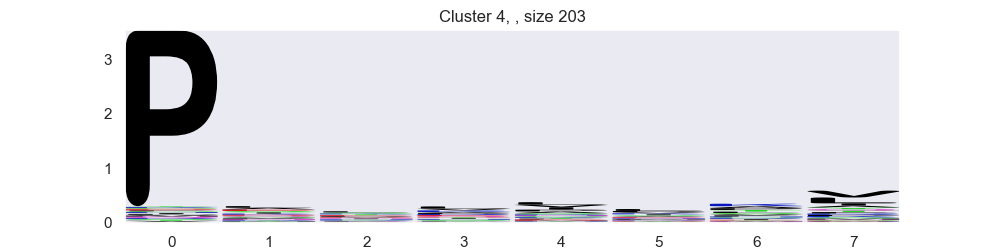

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
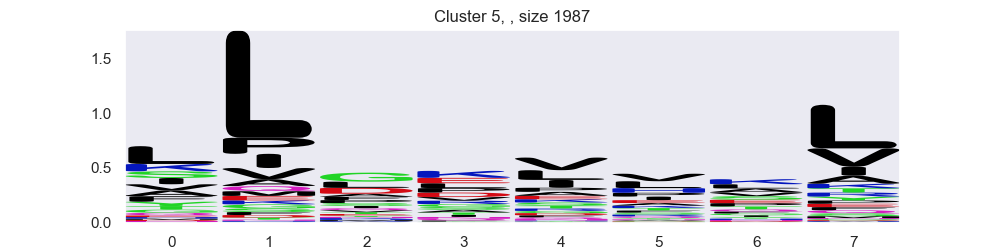

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
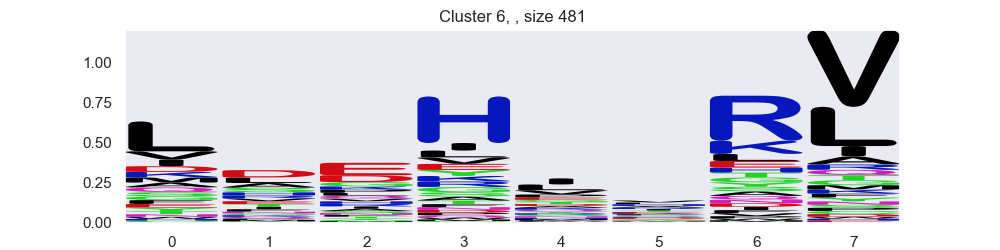

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
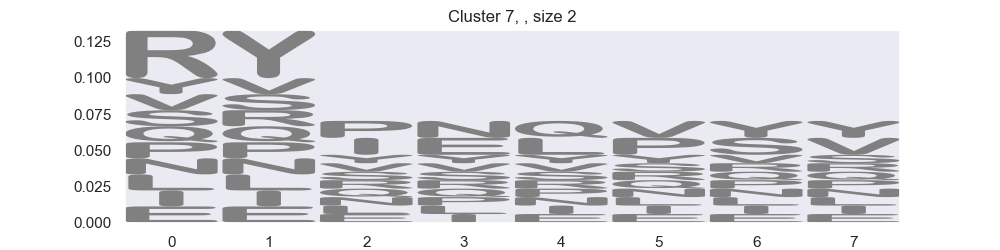

In [62]:
import logomaker
unique_datasets = set(clustered_df.dataset.values)
for cluster_label in unique_labels:
    peptides = clustered_df[clustered_df['label'] == cluster_label]['peptide'].values
    matrix = logomaker.alignment_to_matrix(peptides)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f"Cluster {cluster_label}, , size {len(peptides)}")